# Demand & production forecasting: training and 2026 backtest

Trains the two models, evaluates them on 2026, then trains the final models on **all** data
and saves them for the app:

| model | class | file | predicts |
|---|---|---|---|
| ML 1 demand | `DemandForecaster` (`demand_model.py`) | `models/demand_model.pkl` | `actual_total_load` |
| ML 2 production | `ProductionForecaster` (`production_model.py`) | `models/production_model.pkl` | solar, wind, total production |

```python
from predictions import DemandForecaster, ProductionForecaster
DemandForecaster.load().predict([ts1, ts2, ...])      # any 15-min timestamps up to 7 days ahead
```
or over HTTP: `uvicorn predictions.api:app`, then `POST /forecast/demand`, `/forecast/production`, `/forecast`.

**How the model works**
- Four series (demand in ML 1; solar, wind, other in ML 2), each with LightGBM quantile models (10 / 50 / 90 %):

| series | what drives it | divided by (recent level) |
|---|---|---|
| `actual_total_load` (demand) | calendar, temperature | mean of the last 7 days |
| `solar` | irradiance, cloud, sun angle | max of the last 30 days (tracks capacity growth) |
| `wind_onshore` | wind speed | max of the last 365 days |
| `other_production` = total − solar − wind | dispatched to follow demand | mean of the last 7 days |

- Each sample is a pair (target time `T`, issue time `issued_at`); only data before `issued_at`
  is used, so one model serves every lead time from 15 min to 7 days (`lead_hours` is a feature).
- The model predicts a **correction to a base forecast**: `base = w·last_known + (1−w)·seasonal`
  with `w = exp(−(lead_hours − 0.25)/3)`, i.e. the last value for the next interval, sliding to
  last week / yesterday / the 24 h mean at long leads. Corrections are divided by
  `σ = sqrt(min(lead_hours, 24)/24)`, so short-lead corrections stay small.
- Overfitting control: early stopping on the 3 months before the training cut-off, then a refit.
  The same 3 months calibrate the ranges so they cover about 80 %.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "predictions" else Path.cwd()
sys.path.insert(0, str(ROOT))
from predictions import DemandForecaster, ProductionForecaster
from predictions.core import DAY, MAX_LEAD_STEPS, STEP, WEEK, load_data

REPORT_DIR = ROOT / "predictions" / "reports"
REPORT_DIR.mkdir(exist_ok=True)
TRAIN_END = int(pd.Timestamp("2026-01-01", tz="UTC").timestamp())

# chart colours, fixed order: model, persistence, weekly naive, actual
C_MODEL, C_PERSIST, C_WEEKLY, C_ACTUAL = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

## 1. Load and check the data

In [2]:
data = load_data()
steps = data.timestamp.diff().dropna().value_counts()
print(f"rows: {len(data):,}")
print(f"range: {pd.to_datetime(data.timestamp.min(), unit='s')} -> {pd.to_datetime(data.timestamp.max(), unit='s')} UTC")
print(f"time steps (s): {dict(steps)}" + ("   <- all 15 min, no gaps" if list(steps.index) == [900] else ""))
print(f"invalid rows (blanked in targets): {(data.valid == 0).sum()}")
print(f"train rows: {(data.timestamp < TRAIN_END).sum():,}   test rows (2026): {(data.timestamp >= TRAIN_END).sum():,}")

year = pd.to_datetime(data.timestamp, unit="s").dt.year
data.groupby(year)[["actual_total_load", "solar", "wind_onshore", "other_production"]].agg(["mean", "max"]).round(0)

rows: 140,302
range: 2022-11-07 00:00:00 -> 2026-11-07 11:15:00 UTC
time steps (s): {900.0: np.int64(140301)}   <- all 15 min, no gaps
invalid rows (blanked in targets): 48
train rows: 110,496   test rows (2026): 29,806


actual_total_load          solar         wind_onshore          \
                       mean     max   mean     max         mean     max   
timestamp                                                                 
2022                 6476.0  8276.0   57.0   567.0        776.0  2578.0   
2023                 6092.0  8656.0  167.0   905.0        851.0  2766.0   
2024                 6183.0  8785.0  238.0  1265.0        721.0  2742.0   
2025                 6114.0  8964.0  310.0  1845.0        671.0  2726.0   
2026                 5809.0  9296.0  586.0  3395.0        747.0  2936.0   

          other_production          
                      mean     max  
timestamp                           
2022                5695.0  7097.0  
2023                5416.0  7898.0  
2024                4850.0  7533.0  
2025                4438.0  6689.0  
2026                3883.0  6971.0

Solar's 2026 peak is almost double the training years and demand is about 5 % lower, which is
why every series is divided by its recent level: tree models can't output values outside the
range they were trained on.

## 2. Train both models on data before 2026

In [3]:
t0 = time.time()
demand = DemandForecaster.fit(data, train_end=TRAIN_END)
production = ProductionForecaster.fit(data, train_end=TRAIN_END)
print(f"total {time.time() - t0:.0f} s")

SERIES_COL = {**demand.SERIES_COL, **production.SERIES_COL}


def forecast_all(T, issued):
    return {**demand.forecast(T, issued), **production.forecast(T, issued)}


def history(name):
    return (demand if name == "demand" else production).histories[SERIES_COL[name]]

[demand_model] actual_total_load    439,836 samples   trees/quantile [544, 1997, 544]      59 s


[production_model] solar                437,192 samples   trees/quantile [761, 1428, 167]      44 s


[production_model] wind_onshore         429,434 samples   trees/quantile [205, 362, 211]      19 s


[production_model] other_production     439,836 samples   trees/quantile [176, 126, 114]      12 s


total 135 s


Range calibration factors (per series and lead bucket; > 1 means the raw quantiles were too narrow):

In [4]:
pd.DataFrame({**demand.calibration, **production.calibration},
             index=["0-1 h", "1-6 h", "6-24 h", "1-3 d", "3-7 d"]).round(2).T

,0-1 h,1-6 h,6-24 h,1-3 d,3-7 d
demand,1.18,1.24,1.58,1.79,1.77
solar,1.00,1.00,1.00,1.00,1.00
wind,1.00,1.04,1.12,1.12,1.14
renewables,0.99,1.03,1.11,1.11,1.12
total_production,0.94,0.91,0.92,0.99,1.09


## 3. Evaluation on 2026

For each lead time, **every 2026 interval** is forecast as if issued that long before, and compared with:
- **persistence**: the last known value
- **weekly naive**: same quarter-hour one (or more) weeks earlier

Metrics: MAE (MW), nMAE (% of mean), skill = MAE reduction vs the better baseline, bias, and
coverage of the 10–90 % range (target ≈ 80 %). `renewables` = solar + wind.

In [5]:
LEADS_H = [0.25, 1, 3, 6, 12, 24, 48, 72, 120, 168]
T_test = data.loc[data.timestamp >= TRAIN_END, "timestamp"].to_numpy()

rows = []
for lead in LEADS_H:
    issued = T_test - int((lead - 0.25) * 3600)
    gap = T_test - issued
    fc = forecast_all(T_test, issued)
    for name, pred in fc.items():
        h = history(name)
        y = h.value(T_test)
        persist = h.value(issued - STEP)
        weekly = h.value(T_test - (gap // WEEK + 1) * WEEK)
        ok = ~np.isnan(y) & ~np.isnan(persist) & ~np.isnan(weekly) & ~np.isnan(pred[:, 1])
        mae = np.mean(np.abs(pred[ok, 1] - y[ok]))
        mae_p, mae_w = np.mean(np.abs(persist[ok] - y[ok])), np.mean(np.abs(weekly[ok] - y[ok]))
        rows.append({
            "series": name, "lead_h": lead, "mae": mae,
            "mae_persistence": mae_p, "mae_weekly_naive": mae_w,
            "skill_pct": 100 * (1 - mae / min(mae_p, mae_w)),
            "nmae_pct": 100 * mae / np.mean(y[ok]),
            "bias": np.mean(pred[ok, 1] - y[ok]),
            "coverage_80_pct": 100 * np.mean((pred[ok, 0] <= y[ok]) & (y[ok] <= pred[ok, 2])),
        })
results = pd.DataFrame(rows)
results.to_csv(REPORT_DIR / "eval_2026.csv", index=False, float_format="%.3f")


def pivot(col, digits=0):
    return results.pivot(index="series", columns="lead_h", values=col).round(digits).loc[list(SERIES_COL)]


for col, title in [("mae", "MAE model (MW)"), ("mae_persistence", "MAE persistence (MW)"),
                   ("mae_weekly_naive", "MAE weekly naive (MW)"), ("skill_pct", "skill vs best baseline (%)"),
                   ("nmae_pct", "nMAE (% of mean)"), ("bias", "bias (MW, + = over-forecast)"),
                   ("coverage_80_pct", "10-90 % range coverage (%)")]:
    print(title)
    display(pivot(col, 1 if col == "nmae_pct" else 0))

MAE model (MW)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,49.0,109.0,196.0,218.0,218.0,237.0,254.0,263.0,278.0,291.0
solar,18.0,44.0,80.0,89.0,86.0,87.0,90.0,90.0,93.0,92.0
wind,22.0,75.0,162.0,202.0,205.0,200.0,201.0,198.0,200.0,201.0
renewables,33.0,96.0,195.0,239.0,243.0,243.0,246.0,244.0,248.0,249.0
total_production,74.0,189.0,319.0,358.0,355.0,354.0,375.0,380.0,393.0,394.0


MAE persistence (MW)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,77.0,263.0,687.0,1036.0,958.0,448.0,645.0,680.0,682.0,424.0
solar,41.0,152.0,433.0,802.0,1146.0,146.0,190.0,198.0,208.0,178.0
wind,28.0,90.0,214.0,338.0,479.0,578.0,646.0,633.0,637.0,686.0
renewables,56.0,197.0,519.0,893.0,1209.0,612.0,683.0,678.0,682.0,689.0
total_production,79.0,216.0,471.0,737.0,887.0,655.0,787.0,806.0,804.0,708.0


MAE weekly naive (MW)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,423.0,423.0,423.0,423.0,423.0,424.0,424.0,424.0,424.0,424.0
solar,178.0,178.0,178.0,178.0,178.0,178.0,178.0,178.0,178.0,178.0
wind,686.0,686.0,686.0,686.0,686.0,686.0,686.0,686.0,686.0,686.0
renewables,689.0,689.0,689.0,689.0,689.0,689.0,689.0,689.0,689.0,689.0
total_production,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0


... (4 outputs left out)

bias (MW, + = over-forecast)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,5.0,8.0,24.0,36.0,50.0,63.0,67.0,69.0,64.0,68.0
solar,-2.0,-2.0,-5.0,1.0,-2.0,-7.0,-8.0,-9.0,-11.0,-17.0
wind,-2.0,-12.0,-36.0,-56.0,-66.0,-63.0,-62.0,-62.0,-62.0,-63.0
renewables,-3.0,-14.0,-41.0,-56.0,-69.0,-70.0,-70.0,-71.0,-73.0,-80.0
total_production,-2.0,-1.0,-9.0,-11.0,-13.0,-10.0,-9.0,-4.0,-12.0,-22.0


10-90 % range coverage (%)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,78.0,72.0,74.0,83.0,81.0,82.0,82.0,83.0,84.0,84.0
solar,86.0,84.0,84.0,83.0,81.0,83.0,83.0,83.0,83.0,83.0
wind,80.0,78.0,74.0,82.0,80.0,77.0,76.0,77.0,77.0,77.0
renewables,81.0,79.0,77.0,82.0,79.0,77.0,76.0,77.0,76.0,76.0
total_production,76.0,69.0,69.0,73.0,71.0,75.0,72.0,76.0,76.0,75.0


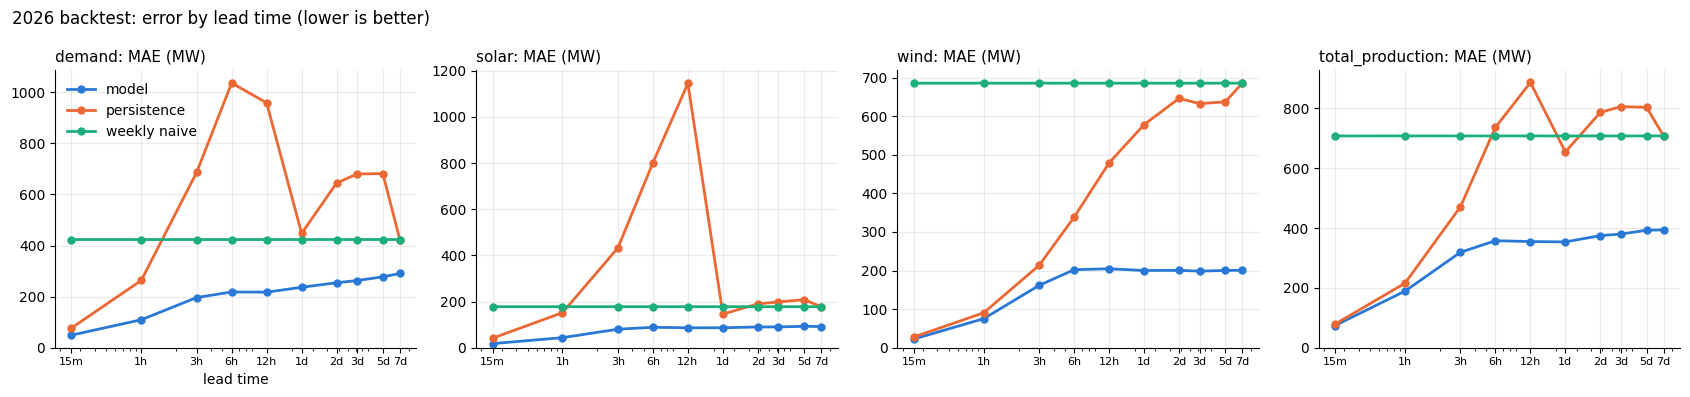

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True)
for ax, name in zip(axes, ["demand", "solar", "wind", "total_production"]):
    r = results[results.series == name]
    ax.plot(r.lead_h, r.mae, color=C_MODEL, lw=2, marker="o", ms=5, label="model")
    ax.plot(r.lead_h, r.mae_persistence, color=C_PERSIST, lw=2, marker="o", ms=5, label="persistence")
    ax.plot(r.lead_h, r.mae_weekly_naive, color=C_WEEKLY, lw=2, marker="o", ms=5, label="weekly naive")
    ax.set_xscale("log")
    ax.set_xticks(LEADS_H, ["15m", "1h", "3h", "6h", "12h", "1d", "2d", "3d", "5d", "7d"], fontsize=8)
    ax.set_title(f"{name}: MAE (MW)", loc="left", fontsize=11)
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False)
axes[0].set_xlabel("lead time")
fig.suptitle("2026 backtest: error by lead time (lower is better)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(REPORT_DIR / "mae_by_lead.png", dpi=110)
plt.show()

### Example weeks
Full 7-day forecasts issued on a Monday 00:00 UTC, against what actually happened.

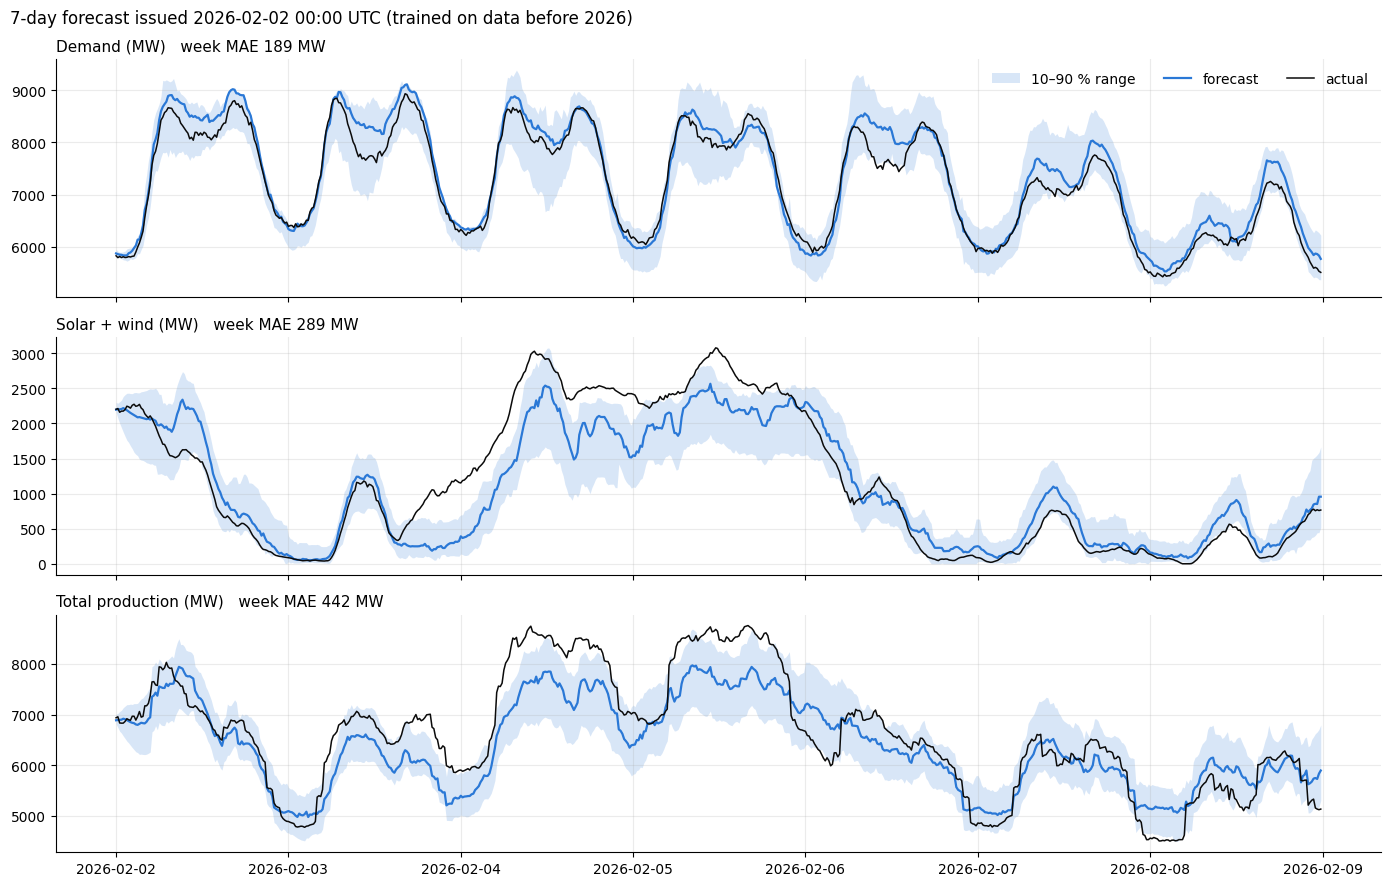

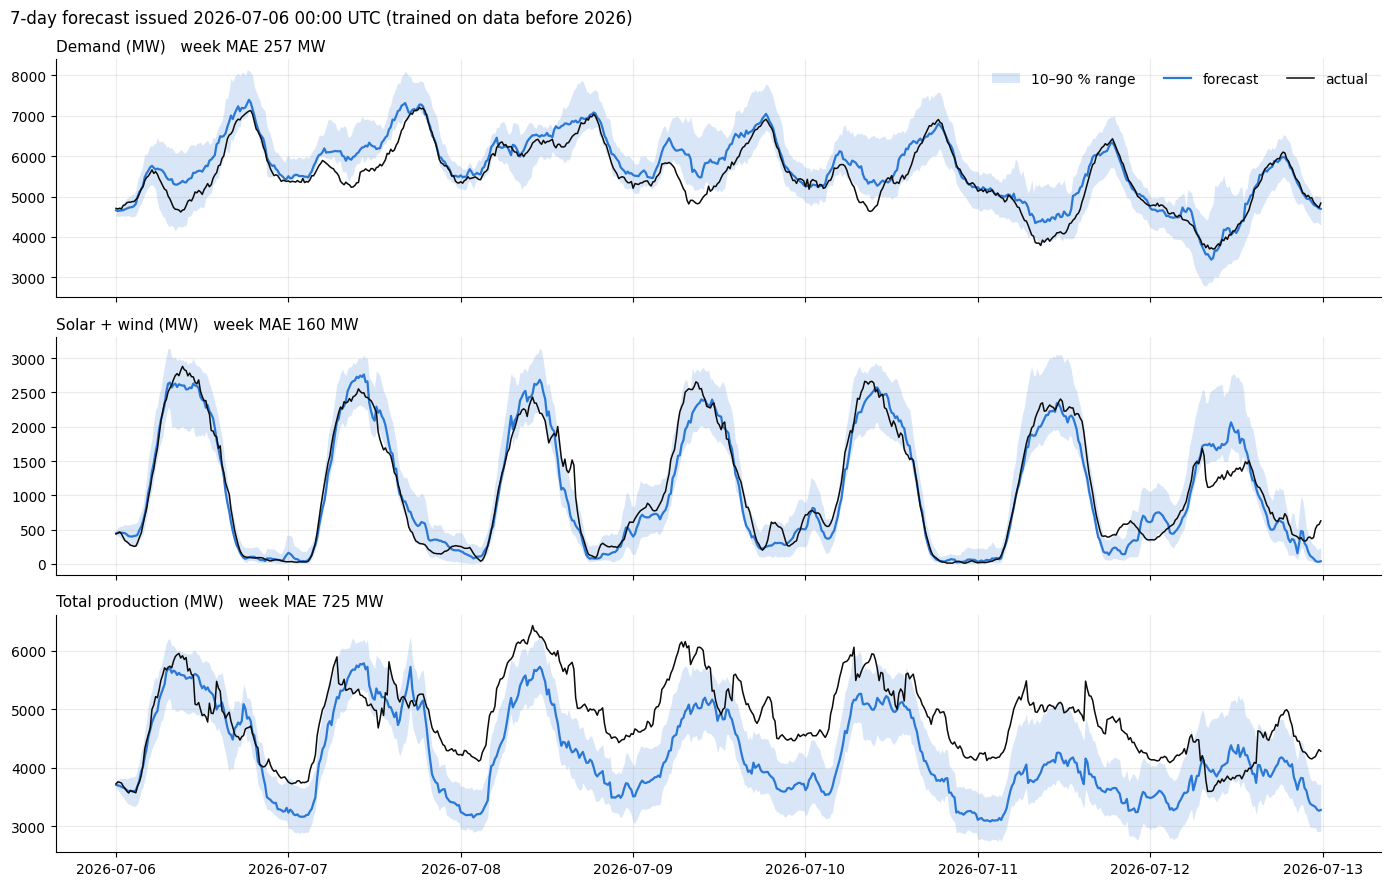

In [7]:
def plot_week(monday):
    issued = int(pd.Timestamp(monday, tz="UTC").timestamp())
    T = issued + np.arange(MAX_LEAD_STEPS) * STEP
    fc = forecast_all(T, issued)
    x = pd.to_datetime(T, unit="s")
    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
    for ax, name, title in zip(axes, ["demand", "renewables", "total_production"],
                               ["Demand", "Solar + wind", "Total production"]):
        y = history(name).value(T)
        p = fc[name]
        ax.fill_between(x, p[:, 0], p[:, 2], color=C_MODEL, alpha=0.18, lw=0, label="10–90 % range")
        ax.plot(x, p[:, 1], color=C_MODEL, lw=1.6, label="forecast")
        ax.plot(x, y, color=C_ACTUAL, lw=1.1, label="actual")
        ax.set_title(f"{title} (MW)   week MAE {np.nanmean(np.abs(p[:, 1] - y)):.0f} MW", loc="left", fontsize=11)
    axes[0].legend(frameon=False, ncol=3, loc="upper right")
    fig.suptitle(f"7-day forecast issued {monday} 00:00 UTC (trained on data before 2026)", x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(REPORT_DIR / f"week_{monday}.png", dpi=110)
    plt.show()


for monday in ["2026-02-02", "2026-07-06"]:
    plot_week(monday)

### What the models use
Share of total split gain in each median model (%).

In [8]:
imp = pd.DataFrame({t: pd.Series(m["boosters"][0.5].feature_importance("gain"), index=m["features"])
                    for t, m in {**demand.models, **production.models}.items()})
(100 * imp / imp.sum()).round(1).sort_values("actual_total_load", ascending=False)

,actual_total_load,solar,wind_onshore,other_production
doy_sin,13.6,3.0,2.8,9.4
doy_cos,11.4,12.2,3.7,7.5
lead_hours,11.1,5.3,6.6,8.2
temperature_2m,8.1,5.7,2.3,2.8
quarter_of_day,6.8,9.8,0.7,7.6
base,5.2,8.6,5.5,7.3
weekday,5.0,0.6,1.1,4.7
mean_1d,5.0,2.8,26.7,8.7
shortwave_radiation,4.5,8.2,2.3,5.5
lag_week,4.3,2.3,1.0,17.1


## 4. Final models: train on all data and save
Same recipe, cut-off = end of the data (the last 3 months are used for early stopping and
calibration, then included in the refit). These are the models the app and API load.

In [9]:
t0 = time.time()
for cls in (DemandForecaster, ProductionForecaster):
    print(f"saved -> {cls.fit(data).save()}")
print(f"total {time.time() - t0:.0f} s")

[demand_model] actual_total_load    559,000 samples   trees/quantile [581, 1399, 477]      61 s


saved -> C:\Users\teodo\Desktop\smarthack2026\GitRekt\predictions\models\demand_model.pkl


[production_model] solar                556,317 samples   trees/quantile [593, 1603, 1150]      84 s


[production_model] wind_onshore         548,614 samples   trees/quantile [846, 454, 123]      45 s


[production_model] other_production     559,000 samples   trees/quantile [56, 856, 205]      32 s


saved -> C:\Users\teodo\Desktop\smarthack2026\GitRekt\predictions\models\production_model.pkl
total 225 s


## 5. Use the saved models
`predict()` takes any timestamps (unsorted, irregular, snapped to 15 min) from `issued_at` up to
7 days later. Weather per timestamp: archive in `dataset.csv` → live Open-Meteo forecast
(≤ 16 days) → climatology.

In [10]:
demand_model = DemandForecaster.load()
production_model = ProductionForecaster.load()
now = demand_model.last_known_ts + STEP
ts = [now, now + 900, now + 3 * 3600, now + DAY + 1234, now + 3 * DAY, now + 7 * DAY - STEP]
display(demand_model.predict(ts))
production_model.predict(ts)

,timestamp,time_utc,lead_hours,demand_mw,demand_low_mw,demand_high_mw,weather_source
0,1794050100,2026-11-07 11:15:00,0.2,4764.9,4555.8,4808.5,archive
1,1794051000,2026-11-07 11:30:00,0.5,4858.6,4645.8,4957.7,forecast
2,1794060900,2026-11-07 14:15:00,3.2,6070.3,5748.9,6600.8,forecast
3,1794137400,2026-11-08 11:30:00,24.5,4993.0,4186.1,5687.6,forecast
4,1794309300,2026-11-10 11:15:00,72.2,7276.6,6704.7,7827.5,forecast
5,1794654000,2026-11-14 11:00:00,168.0,6585.6,4995.5,7258.0,forecast


,timestamp,time_utc,lead_hours,solar_mw,solar_low_mw,solar_high_mw,wind_mw,wind_low_mw,wind_high_mw,prod_low_mw,prod_high_mw,total_mw,total_low_mw,total_high_mw,weather_source
0,1794050100,2026-11-07 11:15:00,0.2,1906.6,1825.1,1980.3,2588.4,2527.3,2700.9,4395.6,4621.7,7142.6,6984.6,7313.5,archive
1,1794051000,2026-11-07 11:30:00,0.5,1849.9,1765.2,1997.1,2537.8,2455.0,2664.9,4273.7,4576.2,7049.9,6884.0,7320.7,forecast
2,1794060900,2026-11-07 14:15:00,3.2,315.0,73.7,458.5,2228.2,1720.2,2494.2,2003.9,2834.9,6161.6,5278.2,6801.0,forecast
3,1794137400,2026-11-08 11:30:00,24.5,1937.0,1676.7,2051.5,121.0,0.0,896.2,1690.4,2821.1,4770.4,3987.2,5535.5,forecast
4,1794309300,2026-11-10 11:15:00,72.2,1057.2,864.7,1321.9,163.3,89.5,1074.7,958.7,2166.7,4700.2,4047.5,5674.4,forecast
5,1794654000,2026-11-14 11:00:00,168.0,501.0,468.8,946.3,1573.8,1146.6,2427.8,1660.0,3085.0,5394.5,4191.3,6505.5,forecast
